In [1]:
import alphashape
import numpy as np
import regionmask
import xarray as xr

mesh_nc = xr.open_dataset("inputs/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.nc")
alpha_shape = alphashape.alphashape(
    np.column_stack([mesh_nc.mesh2d_node_x.values, mesh_nc.mesh2d_node_y.values])[
        ::5, :
    ],
    10,
)
my_region = regionmask.Regions([alpha_shape], name="my_region")
my_region

<regionmask.Regions 'my_region'>
overlap:  None

Regions:
0 r0 Region0

[1 regions]

iso_contours node/edge counts: {5.0: (1403, 1403), 10.0: (1163, 1163), 15.0: (908, 907), 20.0: (1127, 1126)}
depth 5.0 m: selected 131 points (~5.0 km spacing)
depth 10.0 m: selected 168 points (~5.0 km spacing)
depth 15.0 m: selected 242 points (~5.0 km spacing)
depth 20.0 m: selected 352 points (~5.0 km spacing)
Saved: outputs/contours_txts/5mpoints.txt (131 points)
Saved: outputs/contours_txts/10mpoints.txt (168 points)
Saved: outputs/contours_txts/15mpoints.txt (242 points)
Saved: outputs/contours_txts/20mpoints.txt (352 points)
Saved txt files in: outputs/contours_txts


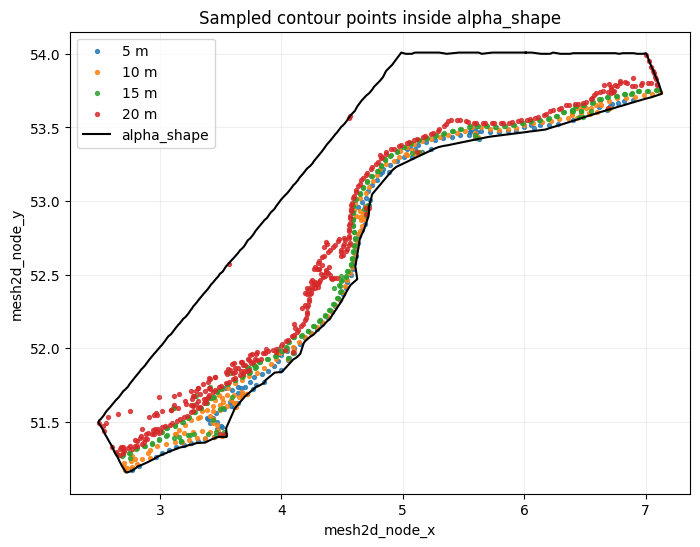

In [2]:
from utils.contour_points import generate_contour_point_files, plot_contour_points

# --- User config: only edit these values ---
depths_to_sample = np.array([5.0, 10.0, 15.0, 20.0])
spacing_m = 5000.0
output_dir = "outputs/contours_txts"

# Optional tuning (keep defaults unless needed)
step = 5
grid_res = 0.02

result, iso_contours = generate_contour_point_files(
    mesh_nc=mesh_nc,
    alpha_shape=alpha_shape,
    depths_m=depths_to_sample,
    spacing_m=spacing_m,
    output_dir=output_dir,
    step=step,
    grid_res=grid_res,
)

fig, ax = plot_contour_points(result=result, alpha_shape=alpha_shape)
print(f"Saved txt files in: {output_dir}")

In [9]:
import os

import numpy as np
from scipy.interpolate import griddata

# Use same settings you pass into generate_contour_point_files
step = 5
grid_res = 0.02

x = mesh_nc.mesh2d_node_x.values
y = mesh_nc.mesh2d_node_y.values
z = mesh_nc.mesh2d_node_z.values

xi = np.arange(np.nanmin(x), np.nanmax(x), grid_res)
yi = np.arange(np.nanmin(y), np.nanmax(y), grid_res)
X, Y = np.meshgrid(xi, yi)

grid_z = griddata(
    points=np.column_stack([x, y]),
    values=z,
    xi=(X, Y),
    method="linear",
)

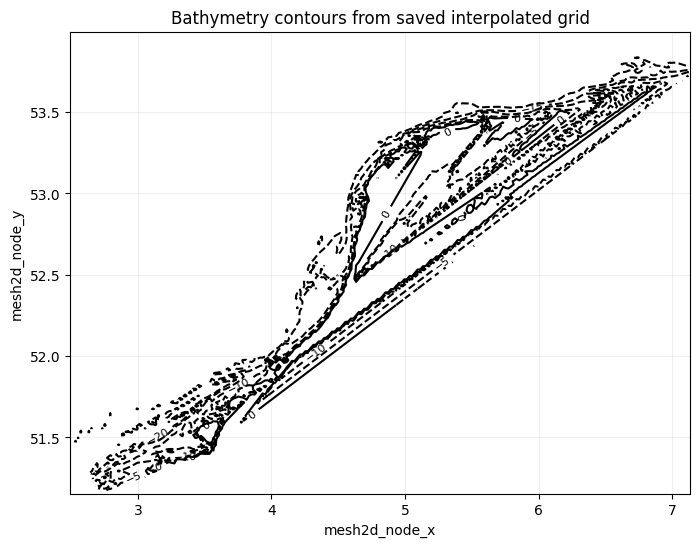

In [10]:
import numpy as np
import matplotlib.pyplot as plt

levels = [-20, -15, -10, -5, 0]  # or your depth levels
plt.figure(figsize=(8, 6))
cs = plt.contour(X, Y, grid_z, levels=levels, colors="k")
plt.clabel(cs, inline=True, fontsize=8)
plt.xlabel("mesh2d_node_x")
plt.ylabel("mesh2d_node_y")
plt.title("Bathymetry contours from saved interpolated grid")
plt.grid(alpha=0.2)
plt.show()